In [1]:

# Phase 4 — Environment verification

import sys
import importlib.util
from pathlib import Path
import shutil

project_folder = Path.cwd().resolve()

if not (project_folder / ".git").exists():
    project_folder = project_folder.parent

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Project folder:", project_folder)
print("Project found:", (project_folder / ".git").exists())

packages = [
    "numpy",
    "pandas",
    "networkx",
    "matplotlib",
    "sklearn",
    "torch",
    "ogb"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")

free_gb = shutil.disk_usage(project_folder).free / (1024 ** 3)
print(f"Available disk space: {free_gb:.2f} GB")


Python: 3.11.9
Python executable: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\.venv\Scripts\python.exe
Project folder: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis
Project found: True
numpy: Installed
pandas: Installed
networkx: Installed
matplotlib: Installed
sklearn: Installed
torch: Installed
ogb: Installed
Available disk space: 162.57 GB


In [2]:

import sys
import subprocess

print("Installing OGB into:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "ogb"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-4000:])
print(result.stderr[-2000:])


Installing OGB into: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\.venv\Scripts\python.exe
Return code: 0
uirement already satisfied: setuptools>=44 in C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\.venv\Lib\site-packages (from outdated>=0.2.0->ogb) (84.0.0)




In [3]:

import ogb
import torch

print("OGB imported successfully.")
print("PyTorch version:", torch.__version__)


OGB imported successfully.
PyTorch version: 2.14.1+cpu


In [5]:

from ogb.nodeproppred import NodePropPredDataset
from pathlib import Path
import numpy as np
import torch

# Locate project root
project_folder = Path.cwd().resolve()

if not (project_folder / ".git").exists():
    project_folder = project_folder.parent

# Create data directory
data_dir = project_folder / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Compatibility fix for OGB's trusted cached dataset
original_torch_load = torch.load

def compatible_torch_load(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return original_torch_load(*args, **kwargs)

torch.load = compatible_torch_load

try:
    # Load the previously downloaded OGBN-Arxiv dataset
    dataset = NodePropPredDataset(
        name="ogbn-arxiv",
        root=str(data_dir)
    )
    graph, labels = dataset[0]
finally:
    # Restore PyTorch's normal, safer behaviour
    torch.load = original_torch_load

print("Dataset loaded successfully!")
print("Number of nodes:", graph["num_nodes"])
print("Number of directed edges:", graph["edge_index"].shape[1])
print("Node feature shape:", graph["node_feat"].shape)
print("Label shape:", labels.shape)
print("Edge index shape:", graph["edge_index"].shape)

print("\nFirst five citation edges:")
print(graph["edge_index"][:, :5].T)


Dataset loaded successfully!
Number of nodes: 169343
Number of directed edges: 1166243
Node feature shape: (169343, 128)
Label shape: (169343, 1)
Edge index shape: (2, 1166243)

First five citation edges:
[[104447  13091]
 [ 15858  47283]
 [107156  69161]
 [107156 136440]
 [107156 107366]]


In [6]:

import pandas as pd
from pathlib import Path

# Locate the dataset's mapping directory
mapping_dir = (
    project_folder
    / "data"
    / "ogbn_arxiv"
    / "mapping"
)

print("Mapping directory exists:", mapping_dir.exists())

if mapping_dir.exists():
    print("\nAvailable mapping files:")
    for file in sorted(mapping_dir.iterdir()):
        print("-", file.name)

# Load the OGB node-ID to paper-ID mapping
mapping_file = mapping_dir / "nodeidx2paperid.csv.gz"

if mapping_file.exists():
    paper_mapping = pd.read_csv(mapping_file)

    print("\nMapping shape:", paper_mapping.shape)
    print("\nFirst five rows:")
    display(paper_mapping.head())

    print("\nColumn names:")
    print(paper_mapping.columns.tolist())
else:
    print("\nMapping file not found at the expected location.")


Mapping directory exists: True

Available mapping files:
- labelidx2arxivcategeory.csv.gz
- nodeidx2paperid.csv.gz
- README.md

Mapping shape: (169343, 2)

First five rows:


,node idx,paper id
0,0,9657784
1,1,39886162
2,2,116214155
3,3,121432379
4,4,231147053



Column names:
['node idx', 'paper id']


In [7]:

# Validate the mapping between graph nodes and paper IDs

print("Total mapping rows:", len(paper_mapping))
print("Unique node IDs:", paper_mapping["node idx"].nunique())
print("Unique paper IDs:", paper_mapping["paper id"].nunique())

print("\nMissing values:")
print(paper_mapping.isna().sum())

expected_nodes = set(range(graph["num_nodes"]))
mapped_nodes = set(paper_mapping["node idx"])

print("\nAll graph nodes mapped:", expected_nodes == mapped_nodes)

assert len(paper_mapping) == graph["num_nodes"]
assert paper_mapping["node idx"].is_unique
assert paper_mapping["paper id"].is_unique
assert not paper_mapping.isna().any().any()
assert expected_nodes == mapped_nodes

print("\nPaper-ID mapping validation passed!")


Total mapping rows: 169343
Unique node IDs: 169343
Unique paper IDs: 169343

Missing values:
node idx    0
paper id    0
dtype: int64

All graph nodes mapped: True

Paper-ID mapping validation passed!


In [10]:

import tarfile
import pandas as pd

# Open the compressed TAR archive
with tarfile.open(text_file, mode="r:gz") as archive:

    # Inspect the files inside
    members = archive.getmembers()

    print("Files inside archive:")
    for member in members:
        print("-", member.name)

    # Find the TSV file
    tsv_members = [
        member for member in members
        if member.isfile() and member.name.endswith(".tsv")
    ]

    if len(tsv_members) != 1:
        raise ValueError(
            f"Expected one TSV file, found {len(tsv_members)}"
        )

    # Read the actual TSV content
    with archive.extractfile(tsv_members[0]) as f:
        paper_text = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["paper id", "title", "abstract"],
            dtype={"paper id": "int64"}
        )

print("\nText dataset loaded successfully!")
print("Shape:", paper_text.shape)
print("Columns:", paper_text.columns.tolist())

print("\nFirst five rows:")
display(paper_text.head())


Files inside archive:
- titleabs.tsv

Text dataset loaded successfully!
Shape: (179719, 3)
Columns: ['paper id', 'title', 'abstract']

First five rows:


,paper id,title,abstract
0,200971,ontology as a source for rule generation,This paper discloses the potential of OWL (Web...
1,549074,a novel methodology for thermal analysis a 3 d...,The semiconductor industry is reaching a fasci...
2,630234,spreadsheets on the move an evaluation of mobi...,The power of mobile devices has increased dram...
3,803423,multi view metric learning for multi view vide...,Traditional methods on video summarization are...
4,1102481,big data analytics in future internet of things,Current research on Internet of Things (IoT) m...


In [11]:

# Step 4.2D — Validate and match paper text

print("Total text records:", len(paper_text))
print("Unique paper IDs:", paper_text["paper id"].nunique())

print("\nMissing values:")
print(paper_text.isna().sum())

print("\nDuplicate paper IDs:",
      paper_text["paper id"].duplicated().sum())

# Validate the text identifiers before joining
assert paper_text["paper id"].notna().all()
assert paper_text["paper id"].is_unique

# Join graph node IDs to titles and abstracts
paper_metadata = paper_mapping.merge(
    paper_text,
    on="paper id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMatching results:")
print(paper_metadata["_merge"].value_counts())

# Check usable text coverage
paper_metadata["has_text"] = (
    paper_metadata["title"].notna()
    & paper_metadata["abstract"].notna()
    & paper_metadata["title"].astype("string").str.strip().ne("")
    & paper_metadata["abstract"].astype("string").str.strip().ne("")
).fillna(False)

matched_count = int(paper_metadata["has_text"].sum())
total_nodes = graph["num_nodes"]

print("\nGraph nodes with usable text:", matched_count)
print("Graph nodes without usable text:",
      total_nodes - matched_count)
print("Usable text coverage:",
      f"{100 * matched_count / total_nodes:.2f}%")

print("\nFirst five matched records:")
display(
    paper_metadata.loc[
        paper_metadata["has_text"],
        ["node idx", "paper id", "title", "abstract"]
    ].head()
)


Total text records: 179719
Unique paper IDs: 179719

Missing values:
paper id    0
title       0
abstract    0
dtype: int64

Duplicate paper IDs: 0

Matching results:
_merge
both          169343
left_only          0
right_only         0
Name: count, dtype: int64

Graph nodes with usable text: 169343
Graph nodes without usable text: 0
Usable text coverage: 100.00%

First five matched records:


,node idx,paper id,title,abstract
0,0,9657784,evasion attacks against machine learning at te...,"In security-sensitive applications, the succes..."
1,1,39886162,how hard is computing parity with noisy commun...,We show a tight lower bound of $\Omega(N \log\...
2,2,116214155,on the absence of the rip in real world applic...,The purpose of this paper is twofold. The firs...
3,3,121432379,a promise theory perspective on data networks,Networking is undergoing a transformation thro...
4,4,231147053,analysis of asymptotically optimal sampling ba...,Over the last 20 years significant effort has ...


In [12]:

import networkx as nx
import numpy as np

# Create a directed citation network
edge_index = graph["edge_index"]

G_directed = nx.DiGraph()
G_directed.add_nodes_from(range(graph["num_nodes"]))
G_directed.add_edges_from(edge_index.T.tolist())

# Create an undirected version for community detection
G_full = G_directed.to_undirected()

print("DIRECTED NETWORK")
print("Nodes:", G_directed.number_of_nodes())
print("Edges:", G_directed.number_of_edges())

print("\nUNDIRECTED NETWORK")
print("Nodes:", G_full.number_of_nodes())
print("Edges:", G_full.number_of_edges())

# Basic network properties
print("\nNETWORK PROPERTIES")
print("Density:", round(nx.density(G_full), 6))
print("Average degree:",
      round(np.mean([d for _, d in G_full.degree()]), 3))

print("Number of connected components:",
      nx.number_connected_components(G_full))

largest_component = max(
    nx.connected_components(G_full),
    key=len
)

print("Largest connected component size:",
      len(largest_component))

print("Largest component percentage:",
      round(
          100 * len(largest_component)
          / G_full.number_of_nodes(),
          2
      ),
      "%"
)


DIRECTED NETWORK
Nodes: 169343
Edges: 1166243

UNDIRECTED NETWORK
Nodes: 169343
Edges: 1157799

NETWORK PROPERTIES
Density: 8.1e-05
Average degree: 13.674
Number of connected components: 1
Largest connected component size: 169343
Largest component percentage: 100.0 %


In [13]:

from collections import deque
import numpy as np
import networkx as nx

RANDOM_SEED = 42
TARGET_NODES = 5000

# Choose a reproducible starting node
rng = np.random.default_rng(RANDOM_SEED)

start_node = int(
    rng.choice(sorted(G_full.nodes()))
)

print("Starting node:", start_node)

# Breadth-first sampling
visited = {start_node}
queue = deque([start_node])

while queue and len(visited) < TARGET_NODES:
    current = queue.popleft()

    for neighbour in sorted(G_full.neighbors(current)):
        if neighbour not in visited:
            visited.add(neighbour)
            queue.append(neighbour)

            if len(visited) >= TARGET_NODES:
                break

# Create the induced subgraph
G_subset = G_full.subgraph(visited).copy()

print("\nSUBSET PROPERTIES")
print("Nodes:", G_subset.number_of_nodes())
print("Edges:", G_subset.number_of_edges())
print("Connected:", nx.is_connected(G_subset))
print("Average degree:",
      round(
          np.mean([d for _, d in G_subset.degree()]),
          3
      ))

print("Density:", round(nx.density(G_subset), 6))

# Verify the sample
assert G_subset.number_of_nodes() == TARGET_NODES
assert nx.is_connected(G_subset)

print("\n5,000-node subset created successfully!")


Starting node: 15114

SUBSET PROPERTIES
Nodes: 5000
Edges: 26953
Connected: True
Average degree: 10.781
Density: 0.002157

5,000-node subset created successfully!


In [14]:

# Step 4.3C — Validate and save the analysis subset

import pandas as pd
from pathlib import Path

# Keep the original OGB node IDs
subset_nodes = sorted(G_subset.nodes())

# Match selected nodes to paper metadata
subset_metadata = paper_metadata[
    paper_metadata["node idx"].isin(subset_nodes)
].copy()

subset_metadata = subset_metadata.sort_values(
    "node idx"
).reset_index(drop=True)

# Validate node and text coverage
assert len(subset_metadata) == G_subset.number_of_nodes()
assert subset_metadata["node idx"].is_unique
assert subset_metadata["has_text"].all()
assert set(subset_metadata["node idx"]) == set(subset_nodes)

print("SUBSET METADATA VALIDATION")
print("Nodes:", G_subset.number_of_nodes())
print("Matched papers:", len(subset_metadata))
print("Papers with usable text:",
      int(subset_metadata["has_text"].sum()))

print("\nSample paper titles:")
display(
    subset_metadata[
        ["node idx", "paper id", "title"]
    ].head(10)
)

# Save reproducible node IDs and text metadata
results_dir = project_folder / "results"
results_dir.mkdir(parents=True, exist_ok=True)

pd.DataFrame({
    "node idx": subset_nodes
}).to_csv(
    results_dir / "arxiv_subset_node_ids.csv",
    index=False
)

subset_metadata[
    ["node idx", "paper id", "title", "abstract"]
].to_csv(
    results_dir / "arxiv_subset_metadata.csv",
    index=False
)

print("\nSubset node IDs and metadata saved successfully!")


SUBSET METADATA VALIDATION
Nodes: 5000
Matched papers: 5000
Papers with usable text: 5000

Sample paper titles:


,node idx,paper id,title
0,0,9657784,evasion attacks against machine learning at te...
1,31,1585744708,learning transformations for clustering and cl...
2,65,1814471488,improved analysis for subspace pursuit algorit...
3,112,1981029888,rappor randomized aggregatable privacy preserv...
4,148,2058503096,efficient synthesis of network updates
5,156,2077286704,the henchman problem measuring secrecy by the ...
6,218,2180882408,diffusing private data over networks
7,226,2223375486,adm cle approach for detecting slow variables ...
8,240,2264830470,map support detection for greedy sparse signal...
9,244,2268938174,supervised dimensionality reduction via distan...



Subset node IDs and metadata saved successfully!


In [15]:

# Step 4.4A — Louvain community detection

import networkx as nx
import pandas as pd
import numpy as np
import time

RANDOM_SEED = 42

# Run Louvain on the undirected 5,000-node subgraph
start_time = time.perf_counter()

louvain_communities = nx.community.louvain_communities(
    G_subset,
    seed=RANDOM_SEED,
    weight=None,
    resolution=1
)

louvain_runtime = time.perf_counter() - start_time

# Calculate modularity
louvain_modularity = nx.community.modularity(
    G_subset,
    louvain_communities,
    weight=None
)

# Community sizes
community_sizes = sorted(
    [len(c) for c in louvain_communities],
    reverse=True
)

print("LOUVAIN RESULTS")
print("Number of communities:", len(louvain_communities))
print("Modularity:", round(louvain_modularity, 4))
print("Runtime (seconds):", round(louvain_runtime, 4))

print("\nCOMMUNITY SIZES")
print("Largest community:", max(community_sizes))
print("Smallest community:", min(community_sizes))
print("Average community size:",
      round(np.mean(community_sizes), 2))

print("\nTop 10 community sizes:")
print(community_sizes[:10])

# Validate that every node belongs to exactly one community
assigned_nodes = [
    node
    for community in louvain_communities
    for node in community
]

assert len(assigned_nodes) == G_subset.number_of_nodes()
assert len(set(assigned_nodes)) == G_subset.number_of_nodes()

print("\nLouvain community assignment validated!")


LOUVAIN RESULTS
Number of communities: 15
Modularity: 0.7065
Runtime (seconds): 1.8198

COMMUNITY SIZES
Largest community: 804
Smallest community: 10
Average community size: 333.33

Top 10 community sizes:
[804, 714, 617, 595, 475, 457, 275, 246, 198, 183]

Louvain community assignment validated!


In [16]:

# Step 4.4B — Label Propagation community detection

import time
import networkx as nx
import numpy as np

RANDOM_SEED = 42

start_time = time.perf_counter()

lpa_communities = list(
    nx.community.asyn_lpa_communities(
        G_subset,
        weight=None,
        seed=RANDOM_SEED
    )
)

lpa_runtime = time.perf_counter() - start_time

# Calculate modularity
lpa_modularity = nx.community.modularity(
    G_subset,
    lpa_communities,
    weight=None
)

# Community sizes
lpa_sizes = sorted(
    [len(c) for c in lpa_communities],
    reverse=True
)

print("LABEL PROPAGATION RESULTS")
print("Number of communities:", len(lpa_communities))
print("Modularity:", round(lpa_modularity, 4))
print("Runtime (seconds):", round(lpa_runtime, 4))

print("\nCOMMUNITY SIZES")
print("Largest community:", max(lpa_sizes))
print("Smallest community:", min(lpa_sizes))
print("Average community size:",
      round(np.mean(lpa_sizes), 2))

print("\nTop 10 community sizes:")
print(lpa_sizes[:10])

# Validate community assignments
assigned_nodes = [
    node
    for community in lpa_communities
    for node in community
]

assert len(assigned_nodes) == G_subset.number_of_nodes()
assert len(set(assigned_nodes)) == G_subset.number_of_nodes()

print("\nLabel Propagation community assignment validated!")


LABEL PROPAGATION RESULTS
Number of communities: 124
Modularity: 0.6605
Runtime (seconds): 1.0434

COMMUNITY SIZES
Largest community: 795
Smallest community: 2
Average community size: 40.32

Top 10 community sizes:
[795, 662, 558, 429, 316, 254, 231, 156, 117, 117]

Label Propagation community assignment validated!


In [17]:

# Step 4.4C — Spectral Clustering

import time
import numpy as np
import networkx as nx

from sklearn.cluster import SpectralClustering

RANDOM_SEED = 42
N_CLUSTERS = len(louvain_communities)

# Ensure a consistent node order
node_order = sorted(G_subset.nodes())

# Build sparse adjacency matrix
adjacency = nx.to_scipy_sparse_array(
    G_subset,
    nodelist=node_order,
    weight=None,
    format="csr",
    dtype=np.float64
)

# Convert to scipy's CSR matrix for sklearn compatibility
from scipy.sparse import csr_matrix
adjacency = csr_matrix(adjacency)

print("Adjacency shape:", adjacency.shape)
print("Number of clusters:", N_CLUSTERS)

# Run spectral clustering
start_time = time.perf_counter()

spectral_model = SpectralClustering(
    n_clusters=N_CLUSTERS,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=RANDOM_SEED,
    n_init=10,
    eigen_solver="arpack"
)

spectral_labels = spectral_model.fit_predict(adjacency)

spectral_runtime = time.perf_counter() - start_time

# Convert cluster labels into communities
spectral_communities = []

for cluster_id in sorted(np.unique(spectral_labels)):
    community = {
        node_order[i]
        for i, label in enumerate(spectral_labels)
        if label == cluster_id
    }
    spectral_communities.append(community)

# Calculate modularity
spectral_modularity = nx.community.modularity(
    G_subset,
    spectral_communities,
    weight=None
)

spectral_sizes = sorted(
    [len(c) for c in spectral_communities],
    reverse=True
)

print("\nSPECTRAL CLUSTERING RESULTS")
print("Number of communities:", len(spectral_communities))
print("Modularity:", round(spectral_modularity, 4))
print("Runtime (seconds):", round(spectral_runtime, 4))

print("\nCOMMUNITY SIZES")
print("Largest community:", max(spectral_sizes))
print("Smallest community:", min(spectral_sizes))
print("Average community size:",
      round(np.mean(spectral_sizes), 2))

print("\nTop 10 community sizes:")
print(spectral_sizes[:10])

assert sum(spectral_sizes) == G_subset.number_of_nodes()
print("\nSpectral community assignment validated!")


Adjacency shape: (5000, 5000)
Number of clusters: 15

SPECTRAL CLUSTERING RESULTS
Number of communities: 15
Modularity: 0.6697
Runtime (seconds): 3.2717

COMMUNITY SIZES
Largest community: 1293
Smallest community: 11
Average community size: 333.33

Top 10 community sizes:
[1293, 1009, 569, 564, 483, 415, 159, 117, 97, 73]

Spectral community assignment validated!


In [18]:

# Step 4.4D — Compare community assignments

import pandas as pd
import numpy as np

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

node_order = sorted(G_subset.nodes())

def communities_to_labels(communities, node_order):
    """Convert a community partition to node-aligned labels."""
    node_to_community = {}

    for community_id, community in enumerate(communities):
        for node in community:
            if node in node_to_community:
                raise ValueError(f"Duplicate node: {node}")
            node_to_community[node] = community_id

    if set(node_to_community) != set(node_order):
        raise ValueError("Community partition does not cover all nodes.")

    return np.array([
        node_to_community[node]
        for node in node_order
    ])

# Convert all partitions to comparable label arrays
louvain_labels = communities_to_labels(
    louvain_communities, node_order
)

lpa_labels = communities_to_labels(
    lpa_communities, node_order
)

spectral_labels_aligned = communities_to_labels(
    spectral_communities, node_order
)

partitions = {
    "Louvain": louvain_labels,
    "Label Propagation": lpa_labels,
    "Spectral Clustering": spectral_labels_aligned
}

# Compare every pair of algorithms
comparison_results = []

algorithm_names = list(partitions)

for i in range(len(algorithm_names)):
    for j in range(i + 1, len(algorithm_names)):

        name_a = algorithm_names[i]
        name_b = algorithm_names[j]

        labels_a = partitions[name_a]
        labels_b = partitions[name_b]

        comparison_results.append({
            "Algorithm A": name_a,
            "Algorithm B": name_b,
            "NMI": normalized_mutual_info_score(
                labels_a, labels_b
            ),
            "ARI": adjusted_rand_score(
                labels_a, labels_b
            )
        })

comparison_df = pd.DataFrame(comparison_results)

print("PAIRWISE COMMUNITY AGREEMENT")
display(comparison_df.round(4))


PAIRWISE COMMUNITY AGREEMENT


,Algorithm A,Algorithm B,NMI,ARI
0,Louvain,Label Propagation,0.7180,0.6092
1,Louvain,Spectral Clustering,0.7146,0.5805
2,Label Propagation,Spectral Clustering,0.6850,0.5395


In [19]:

# Step 4.4E — Stability analysis across random seeds

import time
import numpy as np
import pandas as pd
import networkx as nx

from itertools import combinations
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score

N_RUNS = 10
seeds = range(N_RUNS)

stability_results = []
all_run_labels = {
    "Louvain": [],
    "Label Propagation": [],
    "Spectral Clustering": []
}

for algorithm in all_run_labels:

    print(f"\nRunning {algorithm}...")

    for seed in seeds:

        start_time = time.perf_counter()

        if algorithm == "Louvain":
            communities = nx.community.louvain_communities(
                G_subset,
                seed=seed,
                weight=None
            )

        elif algorithm == "Label Propagation":
            communities = list(
                nx.community.asyn_lpa_communities(
                    G_subset,
                    seed=seed,
                    weight=None
                )
            )

        else:
            model = SpectralClustering(
                n_clusters=N_CLUSTERS,
                affinity="precomputed",
                assign_labels="kmeans",
                random_state=seed,
                n_init=10,
                eigen_solver="arpack"
            )

            labels = model.fit_predict(adjacency)

            communities = [
                {
                    node_order[i]
                    for i, label in enumerate(labels)
                    if label == cluster_id
                }
                for cluster_id in np.unique(labels)
            ]

        runtime = time.perf_counter() - start_time

        modularity = nx.community.modularity(
            G_subset,
            communities,
            weight=None
        )

        labels = communities_to_labels(
            communities,
            node_order
        )

        all_run_labels[algorithm].append(labels)

        stability_results.append({
            "algorithm": algorithm,
            "seed": seed,
            "modularity": modularity,
            "runtime_seconds": runtime,
            "n_communities": len(communities)
        })

        print(
            f"  Seed {seed}: "
            f"Q={modularity:.4f}, "
            f"communities={len(communities)}, "
            f"time={runtime:.2f}s"
        )

# Convert results to a DataFrame
stability_df = pd.DataFrame(stability_results)

# Calculate pairwise ARI between repeated runs
stability_summary = []

for algorithm, label_runs in all_run_labels.items():

    subset = stability_df[
        stability_df["algorithm"] == algorithm
    ]

    pairwise_ari = [
        adjusted_rand_score(a, b)
        for a, b in combinations(label_runs, 2)
    ]

    stability_summary.append({
        "algorithm": algorithm,
        "mean_modularity": subset["modularity"].mean(),
        "std_modularity": subset["modularity"].std(),
        "mean_runtime": subset["runtime_seconds"].mean(),
        "mean_communities": subset["n_communities"].mean(),
        "mean_pairwise_ari": np.mean(pairwise_ari)
    })

stability_summary_df = pd.DataFrame(stability_summary)

print("\nSTABILITY SUMMARY")
display(stability_summary_df.round(4))



Running Louvain...
  Seed 0: Q=0.7066, communities=14, time=2.80s
  Seed 1: Q=0.7025, communities=14, time=2.02s
  Seed 2: Q=0.7068, communities=15, time=1.91s
  Seed 3: Q=0.7016, communities=16, time=1.64s
  Seed 4: Q=0.7080, communities=17, time=2.16s
  Seed 5: Q=0.7063, communities=13, time=1.98s
  Seed 6: Q=0.7043, communities=17, time=2.36s
  Seed 7: Q=0.7081, communities=16, time=2.07s
  Seed 8: Q=0.7017, communities=14, time=4.82s
  Seed 9: Q=0.7033, communities=15, time=1.79s

Running Label Propagation...
  Seed 0: Q=0.6828, communities=118, time=0.84s
  Seed 1: Q=0.6537, communities=134, time=0.78s
  Seed 2: Q=0.6237, communities=140, time=0.99s
  Seed 3: Q=0.6674, communities=118, time=1.44s
  Seed 4: Q=0.6569, communities=128, time=1.17s
  Seed 5: Q=0.6528, communities=113, time=2.21s
  Seed 6: Q=0.6702, communities=129, time=1.13s
  Seed 7: Q=0.6672, communities=105, time=1.06s
  Seed 8: Q=0.6549, communities=123, time=0.92s
  Seed 9: Q=0.6666, communities=118, time=0.83s


,algorithm,mean_modularity,std_modularity,mean_runtime,mean_communities,mean_pairwise_ari
0,Louvain,0.7049,0.0025,2.3535,15.1,0.7972
1,Label Propagation,0.6596,0.0157,1.1368,122.6,0.6125
2,Spectral Clustering,0.6576,0.0319,2.5772,15.0,0.8644


In [20]:

# Step 4.4F — Extend stability analysis from 10 to 30 runs

additional_results = []

for algorithm in all_run_labels:

    print(f"\nRunning additional {algorithm} experiments...")

    for seed in range(10, 30):

        start_time = time.perf_counter()

        if algorithm == "Louvain":
            communities = nx.community.louvain_communities(
                G_subset,
                seed=seed,
                weight=None
            )

        elif algorithm == "Label Propagation":
            communities = list(
                nx.community.asyn_lpa_communities(
                    G_subset,
                    seed=seed,
                    weight=None
                )
            )

        else:
            model = SpectralClustering(
                n_clusters=N_CLUSTERS,
                affinity="precomputed",
                assign_labels="kmeans",
                random_state=seed,
                n_init=10,
                eigen_solver="arpack"
            )

            labels = model.fit_predict(adjacency)

            communities = [
                {
                    node_order[i]
                    for i, label in enumerate(labels)
                    if label == cluster_id
                }
                for cluster_id in np.unique(labels)
            ]

        runtime = time.perf_counter() - start_time

        modularity = nx.community.modularity(
            G_subset,
            communities,
            weight=None
        )

        labels = communities_to_labels(
            communities,
            node_order
        )

        all_run_labels[algorithm].append(labels)

        additional_results.append({
            "algorithm": algorithm,
            "seed": seed,
            "modularity": modularity,
            "runtime_seconds": runtime,
            "n_communities": len(communities)
        })

        print(
            f"  Seed {seed}: Q={modularity:.4f}, "
            f"communities={len(communities)}, "
            f"time={runtime:.2f}s"
        )

# Append new results
stability_df = pd.concat(
    [stability_df, pd.DataFrame(additional_results)],
    ignore_index=True
)

# Recalculate 30-run stability summary
stability_summary = []

for algorithm, label_runs in all_run_labels.items():

    subset = stability_df[
        stability_df["algorithm"] == algorithm
    ]

    pairwise_ari = [
        adjusted_rand_score(a, b)
        for a, b in combinations(label_runs, 2)
    ]

    stability_summary.append({
        "algorithm": algorithm,
        "mean_modularity": subset["modularity"].mean(),
        "std_modularity": subset["modularity"].std(),
        "mean_runtime": subset["runtime_seconds"].mean(),
        "mean_communities": subset["n_communities"].mean(),
        "mean_pairwise_ari": np.mean(pairwise_ari)
    })

stability_summary_df = pd.DataFrame(stability_summary)

print("\nFINAL 30-RUN STABILITY SUMMARY")
display(stability_summary_df.round(4))

print("\nNumber of runs per algorithm:")
print(stability_df.groupby("algorithm").size())



Running additional Louvain experiments...
  Seed 10: Q=0.7068, communities=16, time=2.52s
  Seed 11: Q=0.6978, communities=13, time=3.37s
  Seed 12: Q=0.7011, communities=15, time=1.77s
  Seed 13: Q=0.7050, communities=15, time=1.65s
  Seed 14: Q=0.7054, communities=14, time=2.20s
  Seed 15: Q=0.7031, communities=16, time=2.25s
  Seed 16: Q=0.7021, communities=12, time=2.04s
  Seed 17: Q=0.7030, communities=16, time=2.22s
  Seed 18: Q=0.7049, communities=15, time=2.04s
  Seed 19: Q=0.7029, communities=16, time=2.11s
  Seed 20: Q=0.7047, communities=17, time=2.09s
  Seed 21: Q=0.7041, communities=15, time=3.84s
  Seed 22: Q=0.6971, communities=13, time=1.80s
  Seed 23: Q=0.7024, communities=17, time=2.54s
  Seed 24: Q=0.7029, communities=14, time=2.96s
  Seed 25: Q=0.7071, communities=14, time=2.92s
  Seed 26: Q=0.7037, communities=16, time=2.14s
  Seed 27: Q=0.7040, communities=15, time=1.84s
  Seed 28: Q=0.6924, communities=14, time=1.72s
  Seed 29: Q=0.7059, communities=14, time=2.4

,algorithm,mean_modularity,std_modularity,mean_runtime,mean_communities,mean_pairwise_ari
0,Louvain,0.7035,0.0033,2.3326,14.9333,0.7755
1,Label Propagation,0.6600,0.0151,0.9904,124.8667,0.6427
2,Spectral Clustering,0.6572,0.0311,2.3956,15.0000,0.8632



Number of runs per algorithm:
algorithm
Label Propagation      30
Louvain                30
Spectral Clustering    30
dtype: int64


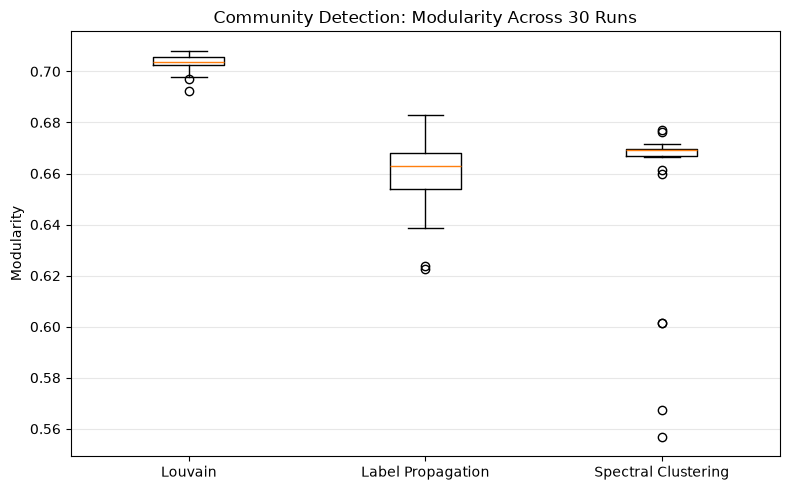

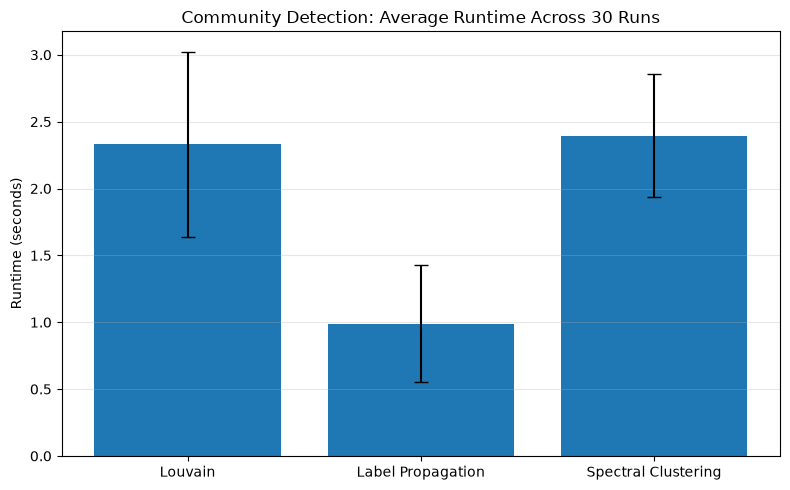

Community detection results and figures saved!


In [21]:

# Step 4.4G — Save results and figures

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

results_dir = project_folder / "results"
figures_dir = project_folder / "figures"

results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

# Validate experiment completeness
assert len(stability_df) == 90
assert (stability_df.groupby("algorithm").size() == 30).all()

# Save numerical results
stability_df.to_csv(
    results_dir / "arxiv_community_stability_runs.csv",
    index=False
)

stability_summary_df.to_csv(
    results_dir / "arxiv_community_stability_summary.csv",
    index=False
)

comparison_df.to_csv(
    results_dir / "arxiv_community_agreement.csv",
    index=False
)

# Figure 1 — Modularity distribution
fig1, ax1 = plt.subplots(figsize=(8, 5))

algorithms = [
    "Louvain",
    "Label Propagation",
    "Spectral Clustering"
]

modularity_data = [
    stability_df.loc[
        stability_df["algorithm"] == algorithm,
        "modularity"
    ].to_numpy()
    for algorithm in algorithms
]

ax1.boxplot(modularity_data, tick_labels=algorithms)
ax1.set_ylabel("Modularity")
ax1.set_title("Community Detection: Modularity Across 30 Runs")
ax1.grid(axis="y", alpha=0.3)

fig1.tight_layout()
fig1.savefig(
    figures_dir / "arxiv_community_modularity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Figure 2 — Runtime comparison
fig2, ax2 = plt.subplots(figsize=(8, 5))

runtime_means = [
    stability_df.loc[
        stability_df["algorithm"] == algorithm,
        "runtime_seconds"
    ].mean()
    for algorithm in algorithms
]

runtime_stds = [
    stability_df.loc[
        stability_df["algorithm"] == algorithm,
        "runtime_seconds"
    ].std()
    for algorithm in algorithms
]

ax2.bar(
    algorithms,
    runtime_means,
    yerr=runtime_stds,
    capsize=5
)

ax2.set_ylabel("Runtime (seconds)")
ax2.set_title("Community Detection: Average Runtime Across 30 Runs")
ax2.grid(axis="y", alpha=0.3)

fig2.tight_layout()
fig2.savefig(
    figures_dir / "arxiv_community_runtime.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Community detection results and figures saved!")
